In [ ]:
import pandas as pd
import numpy as np

import matplotlib as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

In [23]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

In [24]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [25]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


### What is the majority class of Survived?

In [26]:
train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [27]:
actual = train['Survived']
prediction = np.zeros(len(train))
accuracy_score(actual, prediction)

0.6161616161616161

### Survived Count by Sex

In [28]:
train.groupby('Sex')['Survived'].value_counts()

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

### Survived Count by Pclass

In [29]:
train.groupby('Pclass')['Survived'].value_counts()

Pclass  Survived
1       1           136
        0            80
2       0            97
        1            87
3       0           372
        1           119
Name: count, dtype: int64

### Survivied data by Sex and Pclass

In [32]:
train.groupby(['Sex', 'Pclass'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass                 
female 1       0.968085     94
       2       0.921053     76
       3       0.500000    144
male   1       0.368852    122
       2       0.157407    108
       3       0.135447    347

### Survived Distribution by Age

<Axes: xlabel='Age', ylabel='Count'>

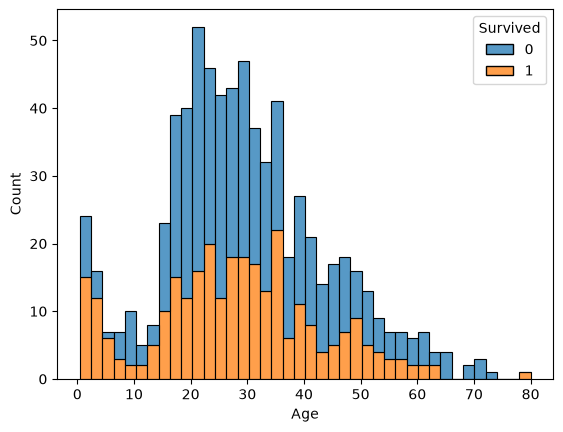

In [36]:
sns.histplot(data=train, x='Age', hue='Survived', bins = 40, multiple='stack')

**Insight:** Passengers's age between 20 and 36 are more likely to survived but which will shrinks the groups with other conditions.

### Survival Rate and Count by Embarked

In [42]:
train.groupby('Embarked')['Survived'].agg(['mean', 'count'])

,mean,count
Embarked,,
C,0.553571,168
Q,0.389610,77
S,0.336957,644


### Survived data by Sex, Pclass, and Embarked

In [41]:
train.groupby(['Sex', 'Pclass', 'Embarked'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass Embarked                 
female 1      C         0.976744     43
              Q         1.000000      1
              S         0.958333     48
       2      C         1.000000      7
              Q         1.000000      2
              S         0.910448     67
       3      C         0.652174     23
              Q         0.727273     33
              S         0.375000     88
male   1      C         0.404762     42
              Q         0.000000      1
              S         0.354430     79
       2      C         0.200000     10
              Q         0.000000      1
              S         0.154639     97
       3      C         0.232558     43
              Q         0.076923     39
              S         0.128302    265

**Insight:** Passenger who is Female, Pclass is 1 or 2 is having a very high survival mean. Beside the female that embarked S, female in third class don't have a low survival mean compared to male.

### Predict it with the patterns from the "Insight" above

In [56]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & ~((train['Pclass'] == 3) & (train['Embarked'] == 'S'))).astype(int)

accuracy_score(actual, prediction)

0.8114478114478114

### Predict it with Female and first class

In [57]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & (train['Pclass'] == 1)).astype(int)

accuracy_score(actual, prediction)

0.7149270482603816

### Apply the patterns from "Insight" on the test datafrane as well

In [58]:
test['Survived'] = ((test['Sex'] == 'female') & ~((test['Pclass'] == 3) & (test['Embarked'] == 'S'))).astype(int)


In [63]:
final_prediction = test[['PassengerId', 'Survived']]
final_prediction.head(10)

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


In [65]:
final_prediction.to_csv('ian_prediction.csv', index=False)